# 07 · E4: decomposition of the Baseline → Slakh-FT improvement

**Question.** The review noted that the Baseline → Slakh-FT comparison confounds the new data with the new codebook loss weights. Notebook 06 trained two control runs that change one factor at a time; this notebook measures how much of the improvement each factor explains, and how certain each part is.

**Method.** The four checkpoints are evaluated on the same 151 Slakh test segments as Table 1 (notebook 01). For every segment the unweighted mean of the per-codebook cross-entropies is computed; this metric does not depend on the loss weights of a run. The improvement splits into three consecutive steps that add up exactly to the total:

| Step | From → to | What changes |
|---|---|---|
| extra training | Baseline → R1 | 25,625 more steps (new LR schedule), same 704 tracks, Baseline weights |
| new data | R1 → R2 | 1229 instead of 704 tracks |
| new loss weights | R2 → Slakh-FT | [1, 1, 2, 2, 2.5, 2.5, 2.5, 2.5] instead of the Baseline weights |

Each difference is paired by segment; its 95% confidence interval is a bootstrap over the test segments (`src/e4_decomposition.py`).

**What it does not show.** The interval covers the choice of test segments, not the randomness of training: each configuration was trained once, so differences of a few hundredths could change with another training seed.

**Kaggle settings:** GPU T4, Internet on. **Inputs:** `slakh-tensors-final`, `secunda-slakh-60-epochs` (Baseline), `secunda-finetuned-on-slakh` (Slakh-FT, model) and `secunda-e4-control-runs` (dataset with `secunda_e4_R1_final_model.pt` and `secunda_e4_R2_final_model.pt` from notebook 06).

In [1]:
# ── Repository bootstrap: make src/ importable on Kaggle and locally ──
# On Kaggle the repository is cloned into /kaggle/working (Internet must be
# enabled in the notebook settings). Locally, set SECUNDA_REPO_DIR to the
# repository root and nothing is cloned.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/DanBracs7/Adaptive-Secunda-Synth.git"
REPO_BRANCH = "revision"  # switch to "main" after merging the revision
REPO_DIR = Path(os.environ.get("SECUNDA_REPO_DIR", "/kaggle/working/Adaptive-Secunda-Synth"))

if not (REPO_DIR / "src").exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )

sys.path.insert(0, str(REPO_DIR / "src"))

commit = subprocess.run(
    ["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"],
    capture_output=True,
    text=True,
).stdout.strip()

print("Repository:", REPO_DIR)
print("Commit:", commit or "unknown (not a git checkout)")

Cloning into '/kaggle/working/Adaptive-Secunda-Synth'...


Repository: /kaggle/working/Adaptive-Secunda-Synth
Commit: 09e81a1


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from audio_dataset import SecundaAudioDataset
from condition_ablation import per_segment_cross_entropy
from e4_decomposition import decomposition_table
from frame_codec import NUM_CODEBOOKS, CodebookSerializer
from paths import get_path, running_on_kaggle, source_roots_for_split
from training_utils import load_checkpoint_model, multi_codebook_metrics, prepare_batch_for_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

RANDOM_SEED = 42            # same crops as notebook 01 / Table 1
BATCH_SIZE = 24
NUM_WORKERS = 2
REPORT_LOSS_WEIGHTS = [1.0, 1.0, 2.0, 2.0, 2.5, 2.5, 2.5, 2.5]   # only for the Table 1 reduction
CODEBOOKS = [f"Q{q}" for q in range(NUM_CODEBOOKS)]


def checkpoint_path(name):
    path = get_path(name)
    if not path.exists() and running_on_kaggle():
        # An uploaded file can end up in a sub-folder of its dataset.
        matches = sorted(Path("/kaggle/input").rglob(path.name))
        path = matches[0] if matches else path
    return path


CHECKPOINTS = {
    "Baseline": checkpoint_path("ckpt_baseline"),
    "R1": checkpoint_path("ckpt_e4_r1"),
    "R2": checkpoint_path("ckpt_e4_r2"),
    "Slakh-FT": checkpoint_path("ckpt_slakh_ft"),
}
for name, path in CHECKPOINTS.items():
    print(f"{name:9s} exists={path.exists()}  {path}")

# Per-codebook test cross-entropy already reported: Baseline and Slakh-FT by
# notebook 01 (Table 1), R1 and R2 by notebook 06 (results/e4/<run>/test_metrics.json).
REPORTED = {
    "Baseline": [3.286917209625244, 4.3396148681640625, 4.921988487243652, 5.38573694229126,
                 5.76570987701416, 6.011356830596924, 6.148679733276367, 6.23488187789917],
    "Slakh-FT": [3.0142502784729004, 4.02440071105957, 4.526853084564209, 4.990567207336426,
                 5.38828706741333, 5.711738109588623, 5.966355323791504, 6.128832817077637],
}
for run in ("R1", "R2"):
    metrics_path = REPO_DIR / "results" / "e4" / run / "test_metrics.json"
    if metrics_path.exists():
        REPORTED[run] = json.loads(metrics_path.read_text(encoding="utf-8"))["per_codebook_loss"]

OUTPUT_DIR = get_path("output_dir") / "e4_decomposition"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Device: Tesla T4
Baseline  exists=True  /kaggle/input/datasets/danielebracoloni/secunda-slakh-60-epochs/secunda_slakh8cb_best_final.pt
R1        exists=True  /kaggle/input/datasets/danielebracoloni/secunda-e4-control-runs/secunda_e4_R1_final_model.pt
R2        exists=True  /kaggle/input/datasets/danielebracoloni/secunda-e4-control-runs/secunda_e4_R2_final_model.pt
Slakh-FT  exists=True  /kaggle/input/models/danielebracoloni/secunda-finetuned-on-slakh/pytorch/default/1/secunda_slakh8cb_finetuneslakh__best.pt


In [3]:
slakh_test = SecundaAudioDataset(
    manifest_path=get_path("manifest"),
    source_roots=source_roots_for_split("test"),
    split="test",
    stage="pretrain",
    segment_seconds=10.0,
    frame_rate=75,
    fixed_start=True,
    seed=RANDOM_SEED,
    samples_per_track=1,
)
test_loader = DataLoader(slakh_test, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
print("Slakh test segments:", len(slakh_test))

Slakh test segments: 151


In [4]:
serializer = CodebookSerializer()


@torch.no_grad()
def evaluate(model, loader):
    """
    Returns the cross-entropy of every segment and codebook [N, Q], and the
    per-codebook values with the Table 1 reduction (mean of per-batch values).
    """
    segment_ce, batch_ce = [], []
    for batch in loader:
        prepared = prepare_batch_for_model(batch, serializer, device)
        logits = model(
            input_codes=prepared["input_codes"],
            input_tension=prepared["input_tension"],
            input_combat=prepared["input_combat"],
            target_tension=prepared["target_tension"],
            target_combat=prepared["target_combat"],
        )
        mean_ce, _ = per_segment_cross_entropy(logits, prepared["target_codes"])
        segment_ce.append(mean_ce.cpu().numpy())
        _, per_codebook_loss, _ = multi_codebook_metrics(logits, prepared["target_codes"], REPORT_LOSS_WEIGHTS)
        batch_ce.append(per_codebook_loss.detach().cpu().numpy())
    return np.concatenate(segment_ce), np.mean(batch_ce, axis=0)


SEGMENT_CE, TABLE1_CE = {}, {}
for name, path in CHECKPOINTS.items():
    model, _ = load_checkpoint_model(path, device)
    SEGMENT_CE[name], TABLE1_CE[name] = evaluate(model, test_loader)
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"{name:9s} unweighted test cross-entropy {SEGMENT_CE[name].mean():.4f}")

segments = pd.concat(
    [pd.DataFrame(values, columns=CODEBOOKS).assign(
        checkpoint=name, segment=np.arange(len(values)),
        track_id=[row["track_id"] for row in slakh_test.rows])
     for name, values in SEGMENT_CE.items()],
    ignore_index=True,
)
segments.to_csv(OUTPUT_DIR / "segment_cross_entropy.csv", index=False)

/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Baseline  unweighted test cross-entropy 5.2878
R1        unweighted test cross-entropy 5.0202
R2        unweighted test cross-entropy 4.9587
Slakh-FT  unweighted test cross-entropy 4.9930


### Check: same numbers as notebooks 01 and 06

With the Table 1 reduction, the per-codebook cross-entropy of every checkpoint must equal the value already reported (Baseline and Slakh-FT: notebook 01; R1 and R2: notebook 06).

In [5]:
print(f"{'':10s}" + "".join(f"{q:>8s}" for q in CODEBOOKS) + f"{'unweighted':>12s}{'max |diff|':>14s}")
for name, values in TABLE1_CE.items():
    reported = REPORTED.get(name)
    difference = "not reported" if reported is None else f"{np.max(np.abs(values - np.asarray(reported))):.1e}"
    print(f"{name:10s}" + "".join(f"{value:8.3f}" for value in values) + f"{values.mean():12.3f}{difference:>14s}")
    if reported is not None and len(slakh_test) == 151:
        assert np.max(np.abs(values - np.asarray(reported))) < 1e-3, name
print("PASS: every checkpoint reproduces its reported evaluation." if len(slakh_test) == 151
      else "Skipped: not the full test split.")

                Q0      Q1      Q2      Q3      Q4      Q5      Q6      Q7  unweighted    max |diff|
Baseline     3.287   4.340   4.922   5.386   5.766   6.011   6.149   6.235       5.262       4.8e-07
R1           2.923   3.940   4.518   5.037   5.492   5.826   6.054   6.168       4.995       4.8e-07
R2           2.848   3.855   4.430   4.959   5.432   5.777   6.025   6.148       4.934       4.8e-07
Slakh-FT     3.014   4.024   4.527   4.991   5.388   5.712   5.966   6.129       4.969       4.8e-07
PASS: every checkpoint reproduces its reported evaluation.


### Decomposition of the improvement

`delta` = change of the unweighted test cross-entropy (negative = better), with a bootstrap 95% CI over the 151 segments; `share` = fraction of the total Baseline → Slakh-FT change explained by the step (the three shares add up to 1); `improved_segments` = fraction of segments whose cross-entropy decreases.

In [6]:
decomposition = pd.DataFrame(decomposition_table(SEGMENT_CE))
total_delta = decomposition.loc[decomposition["step"] == "total", "delta"].item()
decomposition["share"] = decomposition["delta"] / total_delta
decomposition.to_csv(OUTPUT_DIR / "decomposition.csv", index=False)

columns = ["step", "from", "to", "delta", "ci_low", "ci_high", "share", "improved_segments"]
signed = lambda value: f"{value:+.4f}"
percent = lambda value: f"{value:.0%}"
with pd.option_context("display.width", 160):
    print(decomposition[columns].to_string(index=False, formatters={
        "delta": signed, "ci_low": signed, "ci_high": signed, "share": percent, "improved_segments": percent}))

            step     from       to   delta  ci_low ci_high share improved_segments
  extra training Baseline       R1 -0.2675 -0.2747 -0.2602   91%              100%
        new data       R1       R2 -0.0615 -0.0666 -0.0574   21%              100%
new loss weights       R2 Slakh-FT +0.0342 +0.0317 +0.0368  -12%                1%
           total Baseline Slakh-FT -0.2948 -0.3032 -0.2863  100%              100%


### Which codebooks each step changes

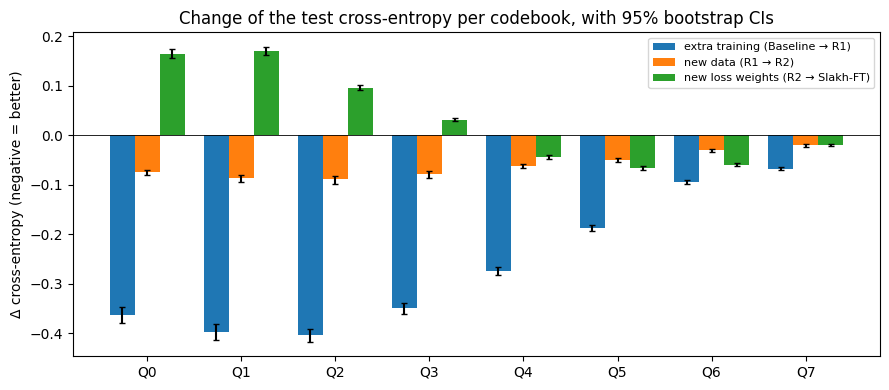

            step     Q0     Q1     Q2     Q3     Q4     Q5     Q6     Q7
  extra training -0.364 -0.398 -0.404 -0.350 -0.275 -0.187 -0.095 -0.067
        new data -0.075 -0.087 -0.089 -0.079 -0.062 -0.050 -0.030 -0.021
new loss weights +0.165 +0.170 +0.096 +0.031 -0.043 -0.066 -0.060 -0.019


In [7]:
steps = decomposition[decomposition["step"] != "total"]
x = np.arange(NUM_CODEBOOKS)
width = 0.8 / len(steps)
figure, axis = plt.subplots(figsize=(9, 4))
for index, (_, row) in enumerate(steps.iterrows()):
    values = np.array([row[f"delta_q{q}"] for q in range(NUM_CODEBOOKS)])
    errors = np.array([[row[f"delta_q{q}"] - row[f"q{q}_low"], row[f"q{q}_high"] - row[f"delta_q{q}"]]
                       for q in range(NUM_CODEBOOKS)]).T
    axis.bar(x + (index - len(steps) / 2 + 0.5) * width, values, width, yerr=errors, capsize=2,
             label=f"{row['step']} ({row['from']} → {row['to']})")
axis.axhline(0, color="black", linewidth=0.6)
axis.set_xticks(x)
axis.set_xticklabels(CODEBOOKS)
axis.set_ylabel("Δ cross-entropy (negative = better)")
axis.set_title("Change of the test cross-entropy per codebook, with 95% bootstrap CIs")
axis.legend(fontsize=8)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "decomposition_per_codebook.png", dpi=150)
plt.show()

per_codebook = steps[["step"] + [f"delta_q{q}" for q in range(NUM_CODEBOOKS)]].rename(
    columns={f"delta_q{q}": f"Q{q}" for q in range(NUM_CODEBOOKS)})
with pd.option_context("display.width", 160):
    print(per_codebook.to_string(index=False, float_format=lambda value: f"{value:+.3f}"))

### Validation curves of the control runs

Both runs use the Baseline loss weights and the same validation set (all 166 Slakh validation tracks), so their validation losses are directly comparable (`results/e4/<run>/history.json`, written by notebook 06).

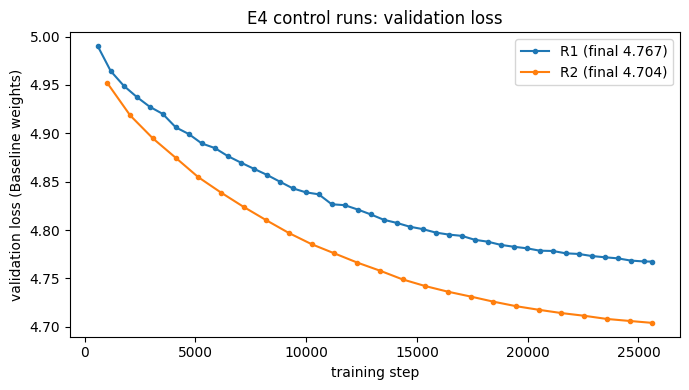

In [8]:
figure, axis = plt.subplots(figsize=(7, 4))
for run in ("R1", "R2"):
    history_path = REPO_DIR / "results" / "e4" / run / "history.json"
    if not history_path.exists():
        print("Missing:", history_path)
        continue
    history = json.loads(history_path.read_text(encoding="utf-8"))
    axis.plot(history["global_step"], history["val_loss"], marker="o", markersize=3,
              label=f"{run} (final {history['val_loss'][-1]:.3f})")
axis.set_xlabel("training step")
axis.set_ylabel("validation loss (Baseline weights)")
axis.set_title("E4 control runs: validation loss")
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "validation_curves.png", dpi=150)
plt.show()

### How to read the result

- A step whose CI excludes 0 changes the test cross-entropy beyond the variability due to the choice of test segments.
- `share` says which factor explains the Baseline → Slakh-FT improvement; a negative share means the step worked against the improvement.
- The per-codebook plot shows where each factor acts: the new loss weights lower the emphasis on Q0–Q1 and raise it on Q4–Q7, so they may trade coarse for fine codebooks.
- One training run per configuration: a difference of a few hundredths with a CI close to 0 should not be over-interpreted.

### Results of this run

**Check.** With the Table 1 reduction every checkpoint reproduces the per-codebook values already reported (max |diff| 4.8e-07), so the four models are evaluated on exactly the segments of Table 1 and notebook 06. The per-segment averages printed above (5.288, 5.020, 4.959, 4.993) are 0.025 higher than the Table 1 values for every checkpoint: the Table 1 reduction averages per-batch values and gives the last, smaller batch (7 segments) the weight of a full batch. The differences between checkpoints agree within 0.002 in the two reductions.

**Decomposition** (per-segment mean over the 151 segments, 95% bootstrap CI):

| Step | Δ unweighted CE | 95% CI | Share | Segments improved |
|---|---|---|---|---|
| extra training (Baseline → R1) | −0.268 | [−0.275, −0.260] | 91% | 100% |
| new data (R1 → R2) | −0.062 | [−0.067, −0.057] | 21% | 100% |
| new loss weights (R2 → Slakh-FT) | +0.034 | [+0.032, +0.037] | −12% | 1% |
| total (Baseline → Slakh-FT) | −0.295 | [−0.303, −0.286] | 100% | 100% |

**Interpretation.**
- The three effects are far from zero with respect to the choice of test segments and have the same sign on almost every segment: the extra training and the new data improve all 151 segments, the new loss weights worsen the unweighted cross-entropy on 149 of them.
- Most of the Baseline → Slakh-FT improvement comes from training longer (91%), the larger dataset adds about a fifth, and the new loss weights work against the unweighted average. Per codebook, the weights raise Q0–Q2 by 0.10–0.17 and lower Q4–Q7 by 0.02–0.07: they trade coarse for fine codebooks, as they were designed to, at a small net cost.
- The validation curves show the same ordering during training: R2 (more data) stays below R1 at every epoch, and both are still decreasing slowly at the end.
- The intervals do not include the randomness of training (one run per configuration). The extra-training effect is an order of magnitude larger than the other two; the data and weight effects, a few hundredths, are consistent across segments but remain results of single runs.